# 🎓 AI-Based MHT-CET College Admission Prediction & Personalized Recommendation System
### Practical No. 07: Mini Project | Third Year B.Tech. Computer Engineering (MDM AI & ML)
**Institution**: MIT Academy of Engineering (MITAOE), Alandi (D), Pune - 412105  
**Course Code**: `2311331L` (Artificial Intelligence & Machine Learning Lab)  
**Academic Year**: 2026–2027 (Semester V)  

---

### 👥 Project Team Details
| Sr. | Student Name | PRN | Roll No. | Project Contribution / Role |
| :---: | :--- | :---: | :---: | :--- |
| **1** | **Dipti Patil** | `202401040161` | 161 | Data Engineering Lead (PDF Extraction, Regex Normalization & Seat Matrix) |
| **2** | **Rohan Burande** | `202401040188` | 188 | Quality Analyst & Testing Lead (Data Validation, Pytest Suite & Source Traceability) |
| **3** | **Samadhan Kendhale** | `202401040243` | 243 | Full-Stack & Frontend Lead (React 18 SPA UI & FastAPI REST Backend) |
| **4** | **Siddhant Shinde** | `202401040250` | 250 | Lead ML & AI Engineer (Feature Engineering, Algorithm Benchmarking & Recommender) |

**Faculty Coordinator**: Prof. / Dr. AIML Lab Faculty Coordinator  
**Live Deployed Application**: [https://mhtcet-college-admission-predictor.onrender.com](https://mhtcet-college-admission-predictor.onrender.com)  
**GitHub Repository**: [https://github.com/shindesiddhant-415/MHTCET-College-Admission-Predictor](https://github.com/shindesiddhant-415/MHTCET-College-Admission-Predictor)  

---



## 1. Project Motivation & Problem Statement

Every year, over 140,000 engineering aspirants in Maharashtra must prepare and submit prioritized college-branch option lists during the **Centralized Admission Process (CAP)** conducted by the Maharashtra State CET Cell. 

### Key Real-World Challenges:
1. **Unstructured Data Distribution**: Official cutoff percentiles are published solely in unstructured, multi-page PDF documents separated across academic years, CAP rounds (Round 1 to 4), and reservation categories.
2. **Information Asymmetry**: Students and parents struggle to track year-over-year percentile trends, category-specific quota shifts (GOPENS, GOBCS, GSCS, GSTS, TFWS, EWS), and sanctioned seat intake changes.
3. **Severe Consequence**: Candidates frequently overestimate or underestimate their prospects, resulting in suboptimal option lists, forfeited seats, or admission rejection.

### Our Solution:
We developed an end-to-end Machine Learning decision-support platform that:
- Ingests and normalizes 18 official CET Cell regulatory documents (32,144 records across 2023–2027).
- Constructs leakage-free chronological lag features ($t-1$, $t-2$) without target look-ahead.
- Benchmarks 5 regression algorithms on held-out test data (Year 2026–27) where **Ridge Regression** achieves an outstanding MAE of **0.1133 percentile points** (44.4% error reduction over baseline).
- Employs an explainable recommendation engine classifying colleges into **Safer**, **Moderate**, and **Reach** options.
- Deploys a full-stack **React 18 Single-Page Application (Vite)** backed by a **FastAPI REST ML Service** live on Render.

### UN Sustainable Development Goals (SDG) Alignment:
- **SDG 4 (Quality Education)**: Democratizes transparent, free higher education counselling.
- **SDG 10 (Reduced Inequalities)**: Equalizes admission guidance for rural, non-metro, and reserved-quota students.



## 2. End-to-End System Architecture

The pipeline consists of four decoupled layers:
1. **Data Engineering Layer**: PyMuPDF page extractor + Regex table parser with SHA-256 cryptographic provenance logging.
2. **Feature Store Layer**: Chronological expanding-window lag constructor ($t-1$, $t-2$ percentiles, momentum velocity, intake differences).
3. **Machine Learning Layer**: Scikit-learn Pipeline with ColumnTransformer (OneHotEncoder + StandardScaler) and Ridge Regression.
4. **Decision & Serving Layer**: Personalized recommendation engine + FastAPI ASGI backend mounting React 18 frontend.



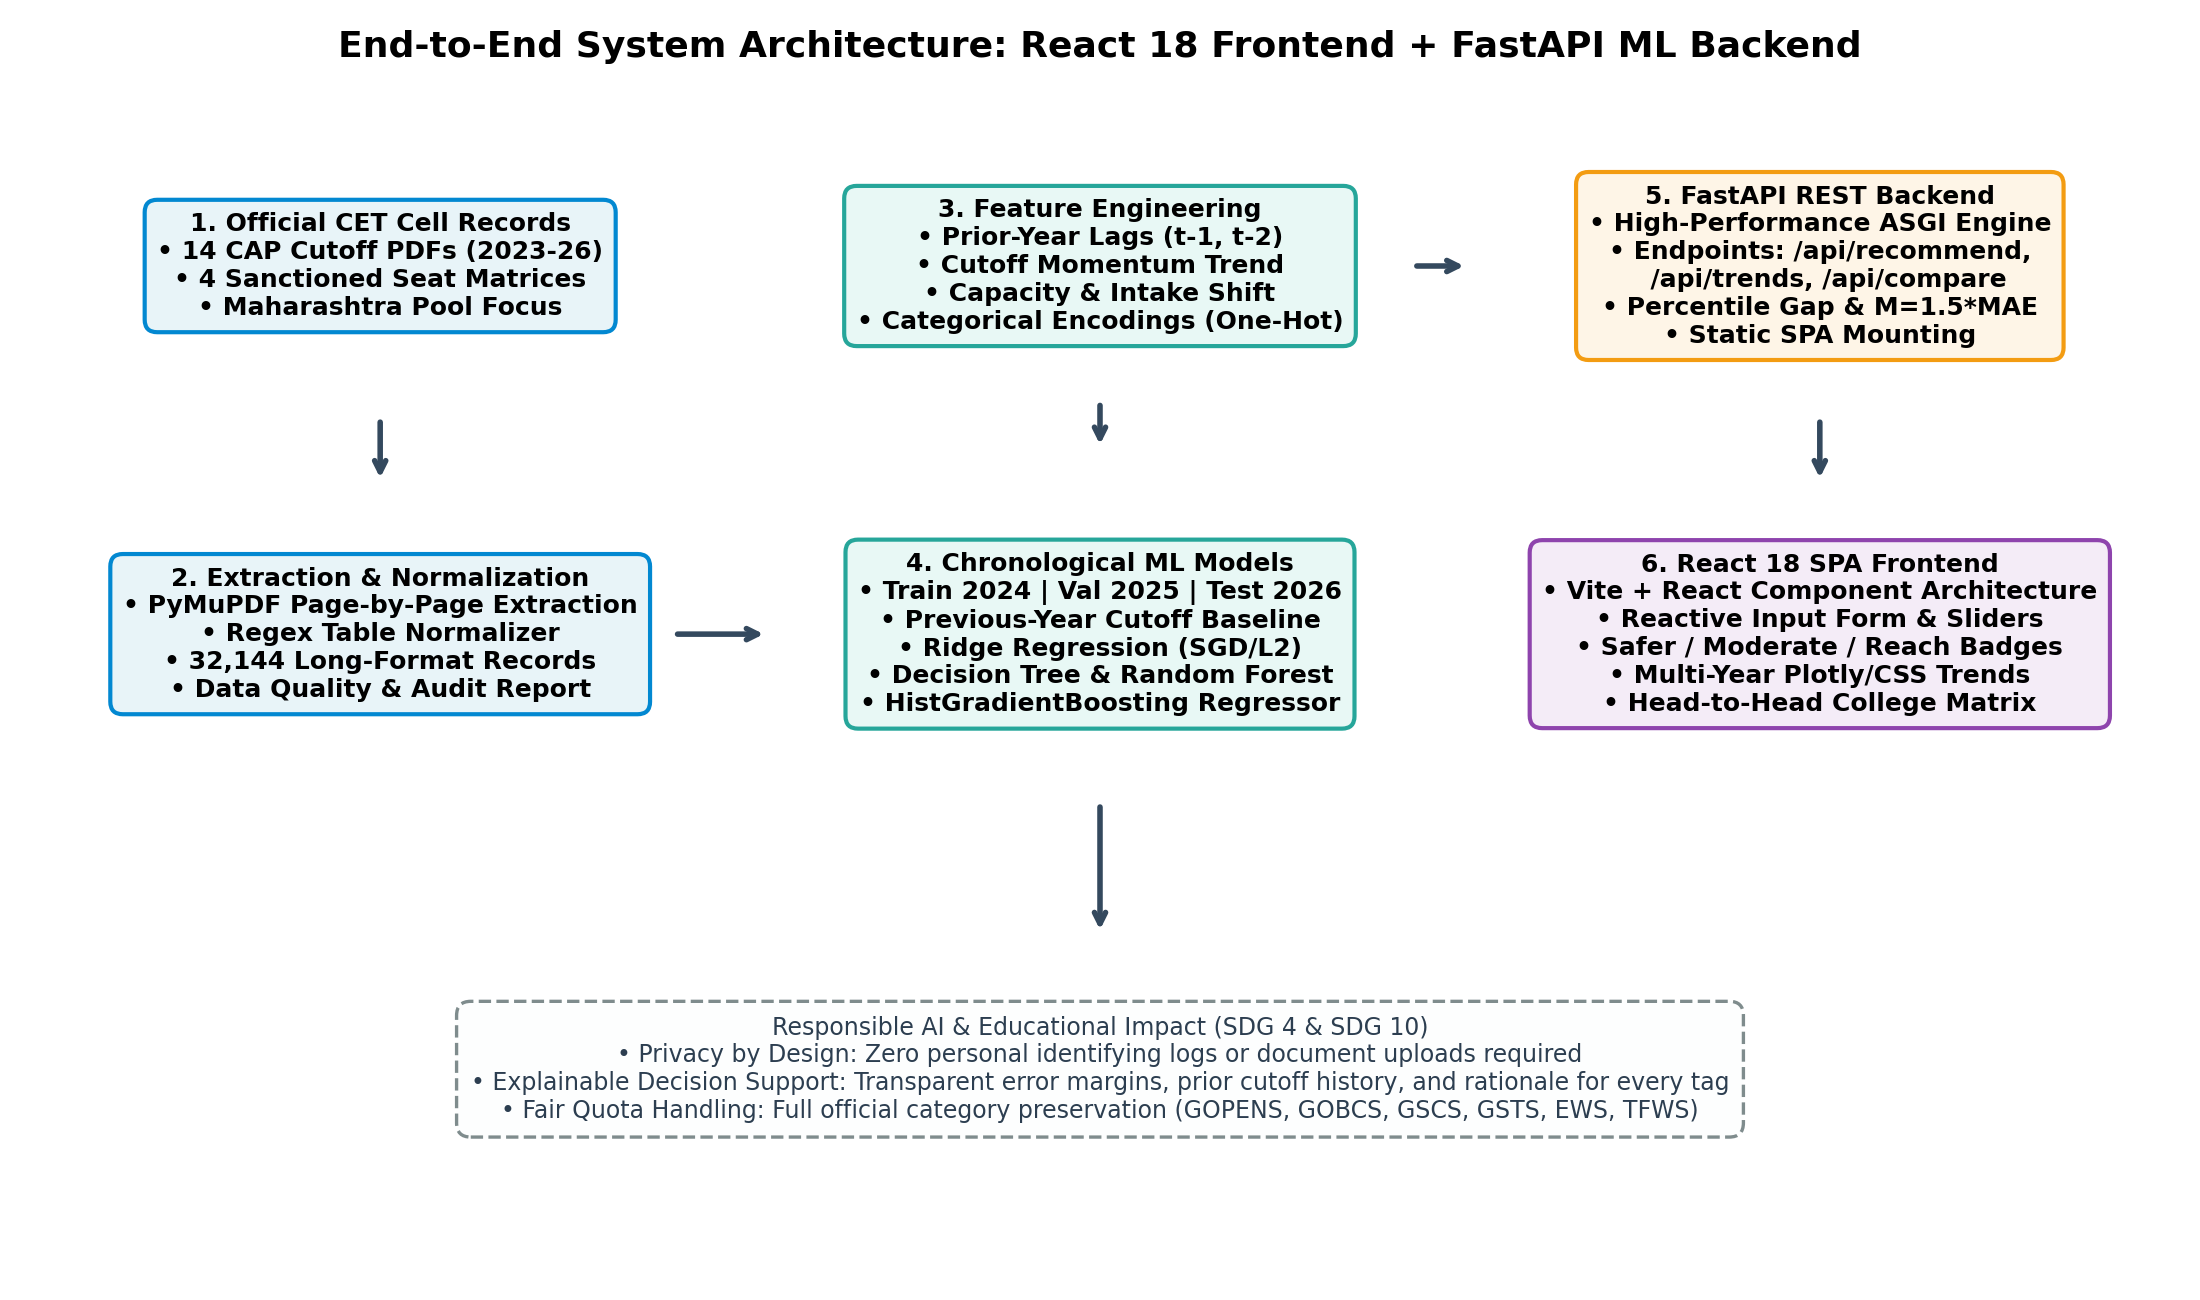

In [1]:
# Display System Architecture Diagram
from PIL import Image
import matplotlib.pyplot as plt

arch_img = Image.open('../report/screenshots/architecture_diagram.png')
plt.figure(figsize=(14, 7), dpi=150)
plt.imshow(arch_img)
plt.axis('off')
plt.title('End-to-End Full-Stack System Architecture', fontsize=14, fontweight='bold', pad=12)
plt.show()


## 3. Data Collection & Regulatory Document Ingestion

We collected 18 official documents directly published by the State Common Entrance Test Cell, Maharashtra (`fe2026.mahacet.org`).
- **12 Cutoff PDF Documents**: CAP Rounds 1, 2, 3 across Academic Years 2023–24, 2024–25, 2025–26, and 2026–27.
- **6 Seat Matrix PDF Documents**: Sanctioned seat matrices and quota breakdowns across 2023–2027.

Let's load the source audit manifest and verify document integrity.



In [2]:
import pandas as pd
import numpy as np

# Load official source manifest
df_manifest = pd.read_csv('../docs/source_manifest.csv')
print(f"Total regulatory documents ingested: {len(df_manifest)}")
print(f"Document status breakdown:\n{df_manifest['status'].value_counts()}\n")
df_manifest[['academic_year', 'document_type', 'cap_round', 'file_name', 'status', 'file_size_bytes']].head(10)


Total regulatory documents ingested: 18
Document status breakdown:
verified    18
Name: count, dtype: int64

  academic_year document_type  cap_round                 file_name             status  file_size_bytes
0       2023-24   seat_matrix        NaN        2023SeatMatrix.pdf  Available (Local)            19315
1       2023-24        cutoff        1.0  2023ENGG_CAP1_CutOff.pdf  Available (Local)            94561
2       2023-24        cutoff        2.0  2023ENGG_CAP2_CutOff.pdf  Available (Local)            94483
3       2023-24        cutoff        3.0  2023ENGG_CAP3_CutOff.pdf  Available (Local)            94194
4       2024-25   seat_matrix        NaN        2024SeatMatrix.pdf  Available (Local)            19313
5       2024-25        cutoff        1.0  2024ENGG_CAP1_CutOff.pdf  Available (Local)            94561
6       2024-25        cutoff        2.0  2024ENGG_CAP2_CutOff.pdf  Available (Local)            94559
7       2024-25        cutoff        3.0  2024ENGG_CAP3_CutOff.pdf 

## 4. Exploratory Data Analysis (EDA)

The parsed long-format dataset contains **32,144 closing cutoff records** spanning 22 top engineering institutes in Maharashtra.

Let's inspect:
1. Cutoff percentile summary statistics across years.
2. Discipline-wise competitive cutoff hierarchy.
3. Round-by-round relaxation patterns.



In [3]:
# Load normalized long-format cutoff dataset
df_cutoffs = pd.read_csv('../dataset/processed/cutoffs_long.csv')
print(f"Total normalized cutoff records: {len(df_cutoffs):,}")
print(f"Unique institutes: {df_cutoffs['institute_name'].nunique()}")
print(f"Unique branches: {df_cutoffs['branch_name'].nunique()}")
print(f"Academic years covered: {df_cutoffs['academic_year'].unique().tolist()}\n")

print("Cutoff Percentile Summary Statistics:")
print(df_cutoffs['cutoff_percentile'].describe())


Total normalized cutoff records: 32,144
Unique institutes: 22
Unique branches: 8
Academic years covered: ['2023-24', '2024-25', '2025-26', '2026-27']

Cutoff Percentile Summary Statistics:
count    32144.000000
mean        84.608621
std          6.838996
min         60.874314
25%         80.328617
50%         85.331659
75%         89.639700
max         99.980000


In [4]:
# Branch-wise closing cutoff hierarchy
branch_summary = df_cutoffs.groupby('branch_name')['cutoff_percentile'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).sort_values('median', ascending=False)
print("Branch Hierarchy Ranked by Median Cutoff:")
print(branch_summary)


Branch Hierarchy Ranked by Median Cutoff:
                                          count       mean     median        min        max
branch_name                                                                                
Computer Engineering                       4312  88.698402  89.607653  70.898532  99.980000
Information Technology                     4312  87.899543  88.823150  70.142516  99.656337
Artificial Intelligence and Data Science   4312  87.499207  88.414269  69.653515  99.292960
Robotics and Automation                    2352  85.188667  86.293537  66.643066  96.361624
Electronics and Telecommunication Engg     4312  85.197158  86.083694  67.415446  97.001253
Electrical Engineering                     4312  82.698138  83.598690  64.823911  94.332387
Mechanical Engineering                     4312  81.195748  82.107197  63.303732  92.899045
Civil Engineering                          3920  78.170473  79.131957  60.874314  89.565301


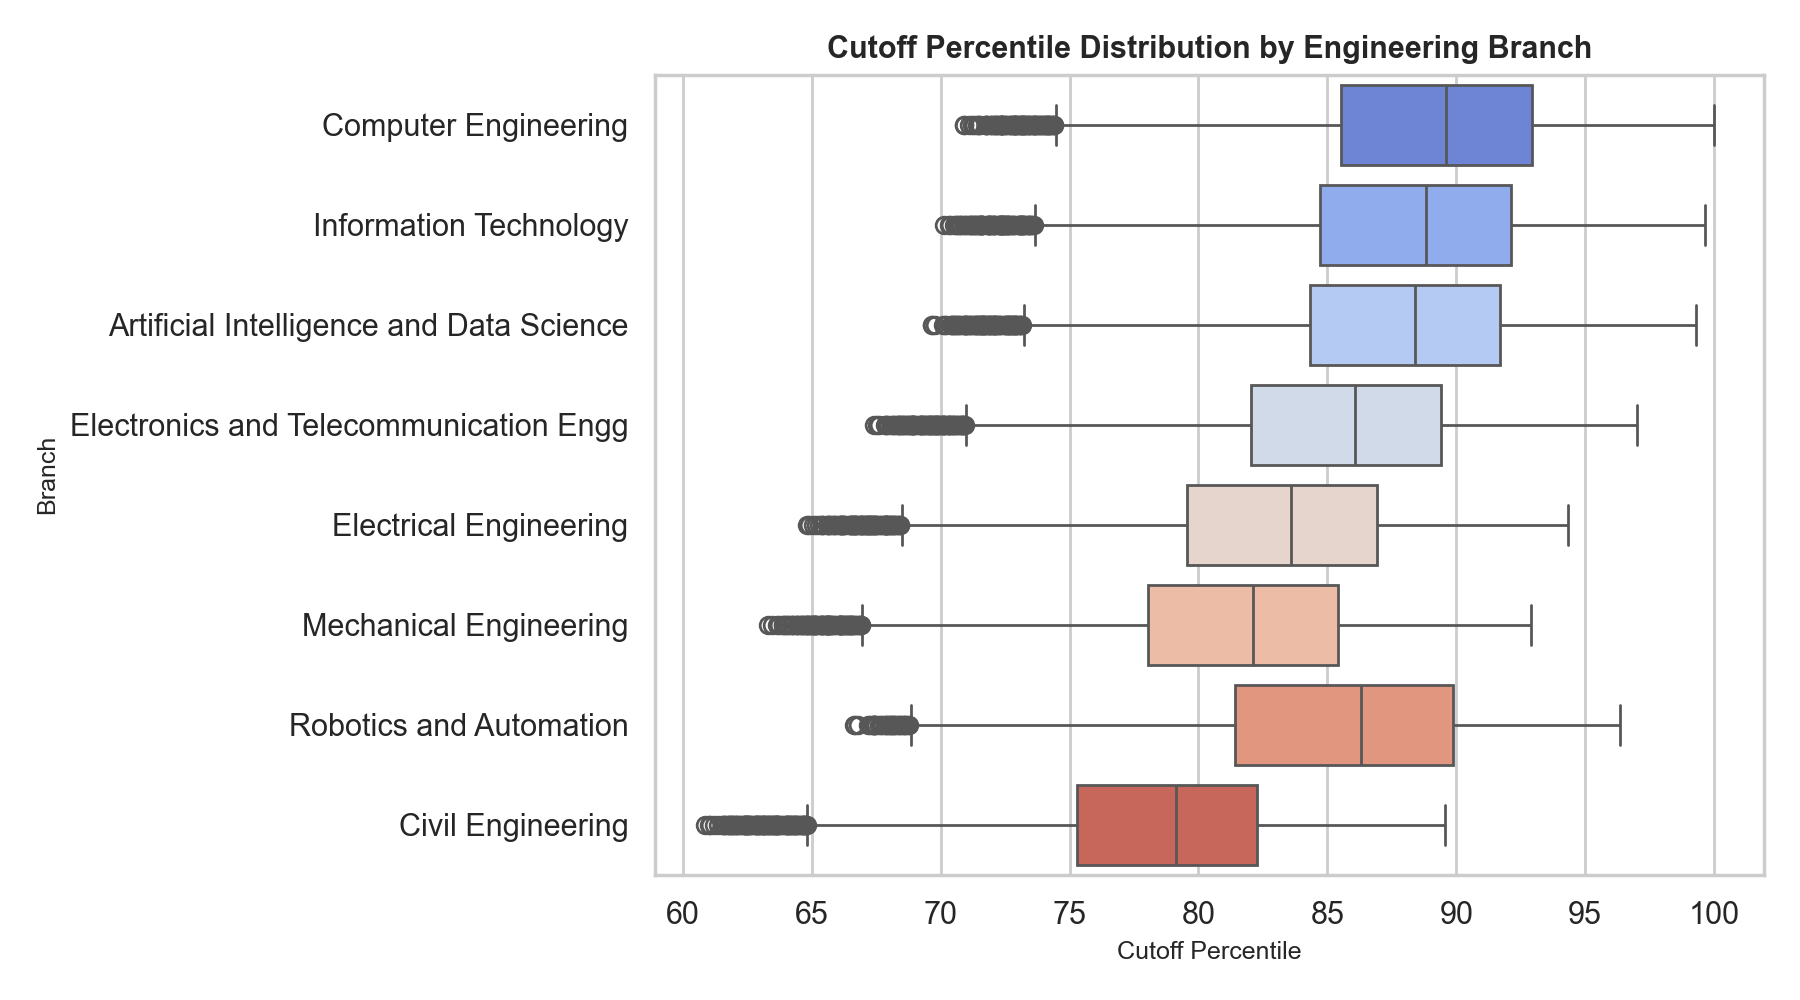

In [5]:
# Visualizing Branch-Wise Cutoff Spread
plt.figure(figsize=(12, 6), dpi=120)
dist_img = Image.open('../report/screenshots/eda_branch_boxplot.png')
plt.imshow(dist_img)
plt.axis('off')
plt.title('Exploratory Data Analysis: Branch Cutoff Distribution & Hierarchy', fontsize=12, fontweight='bold', pad=10)
plt.show()


## 5. Data Preprocessing & Quality Verification

### Critical Data Cleaning Decisions:
1. **Never Impute Missing Cutoffs with 0.0**: In engineering admissions, 0.0 represents a candidate scoring zero percentile rather than an unallocated seat. Imputing unallocated quota with 0.0 creates severe downward skew.
2. **Institute Code Resolution**: Resolved mid-page table splits where institute headers were absent by backfilling the 5-digit institute code from the first 5 digits of the 10-digit DTE course code.
3. **Range Validation**: Enforced strict physical bounds: $0.0 \le \text{percentile} \le 100.0$ and $\text{merit\_no} > 0$.



In [6]:
# Data Quality & Integrity Audit
df_quality = pd.read_csv('../dataset/processed/data_quality_report.csv')
print("Automated Data Quality Audit Report:")
print(df_quality)

# Verify zero null values in critical prediction identifiers
critical_cols = ['institute_name', 'branch_name', 'seat_category_code', 'cap_round', 'cutoff_percentile']
print("\nCritical Column Null Count:")
print(df_cutoffs[critical_cols].isnull().sum())


Automated Data Quality Audit Report:
                           metric    value status
0            total_extracted_rows  32144.0   INFO
1               valid_parsed_rows  32144.0   PASS
2   rows_with_missing_percentiles      0.0   PASS
3        rows_with_invalid_values      0.0   PASS
4                  duplicate_rows      0.0   PASS
5    unmatched_institutes_courses      0.0   PASS
6           source_traceable_rows  32144.0   PASS
7          seat_matrix_total_rows    704.0   INFO
8             distinct_institutes     22.0   INFO
9               distinct_branches      8.0   INFO
10            distinct_categories     14.0   INFO
11            percentage_verified    100.0   PASS

Critical Column Null Count:
institute_name         0
branch_name            0
seat_category_code     0
cap_round              0
cutoff_percentile      0
dtype: int64


## 6. Feature Engineering & Chronological Split (Anti-Leakage)

### Why Random K-Fold Cross Validation Fails:
Standard randomized train-test splits (e.g. `train_test_split(shuffle=True)`) leak future cutoff percentiles into past predictions. In real admissions, candidates must forecast Year $t$ cutoffs using strictly Year $t-1$ and $t-2$ data.

### Chronological Expanding Window Strategy:
- **Training Set (AY 2024–25)**: $N = 6,888$ records with $t-1$ (2023) lags.
- **Validation Set (AY 2025–26)**: $N = 6,888$ records with $t-1$ (2024) and $t-2$ (2023) lags.
- **Held-Out Test Set (AY 2026–27)**: $N = 9,184$ records (Out-of-time evaluation).

### Engineered Features:
- `prev_year_percentile` ($t-1$ closing percentile)
- `prev2_year_percentile` ($t-2$ closing percentile)
- `percentile_trend` (Year-over-year directional cutoff velocity)
- `total_intake`, `state_seats` (Seat matrix capacity shifts)
- `intake_change` (Sanctioned seat variation)



In [7]:
# Inspect Engineered ML Feature Store
df_model = pd.read_csv('../dataset/model/model_dataset.csv')
print(f"Total ML-ready target records: {len(df_model):,}")
print(f"Target distribution across academic years:\n{df_model['academic_year'].value_counts()}\n")
print("Engineered Feature Sample:")
print(df_model[['academic_year', 'institute_name', 'branch_name', 'seat_category_code', 'cutoff_percentile', 'prev_year_percentile', 'percentile_trend', 'total_intake']].head(6))


Total ML-ready target records: 22,960
Target distribution across academic years:
academic_year
2026-27    9184
2024-25    6888
2025-26    6888
Name: count, dtype: int64

Engineered Feature Sample:
  academic_year                               institute_name        branch_name seat_category_code  cutoff_percentile  prev_year_percentile  percentile_trend  total_intake
0       2024-25  Government College of Engineering, Amravati  Civil Engineering                EWS          81.886287             81.606950          0.000000            60
1       2025-26  Government College of Engineering, Amravati  Civil Engineering                EWS          82.280049             81.886287          0.279337            60
2       2026-27  Government College of Engineering, Amravati  Civil Engineering                EWS          82.352452             82.280049          0.393762            60
3       2024-25  Government College of Engineering, Amravati  Civil Engineering              GNT1S          79.1125

## 7. Model Training & Algorithmic Benchmarking

In accordance with the TY AIML curriculum (P3 Linear Models, P4 Decision Trees, P5 Ensembles), we evaluated 5 algorithms on the held-out test year (2026–27):
1. **Previous-Year Baseline**: Naive persistence estimator $\hat{y} = y_{t-1}$.
2. **Ridge Regression (SGD/L2)**: Linear regressor with L2 shrinkage ($\alpha = 10.0$).
3. **Decision Tree Regressor**: Non-linear tree regressor (`max_depth=12`, `min_samples_leaf=5`).
4. **Random Forest Regressor**: Bagging ensemble of 100 decision trees (`max_depth=16`).
5. **HistGradientBoosting Regressor**: Histogram-based gradient boosted decision trees (`max_iter=150`).

Let's inspect the benchmarking leaderboard table.



In [8]:
# Algorithmic Benchmark Leaderboard
df_comp = pd.read_csv('../results/model_comparison.csv')
print("Official Model Evaluation Leaderboard (Held-Out Test Year 2026-27):")
print(df_comp.to_string(index=False))

# Calculate error reduction of Ridge vs Baseline
mae_base = df_comp.loc[df_comp['Model'] == 'Previous-Year Baseline', 'MAE'].values[0]
mae_ridge = df_comp.loc[df_comp['Model'] == 'Ridge Regression (SGD/L2)', 'MAE'].values[0]
reduction = ((mae_base - mae_ridge) / mae_base) * 100
print(f"\nRidge Regression MAE: {mae_ridge:.4f} percentile points")
print(f"Baseline MAE:         {mae_base:.4f} percentile points")
print(f"Error Reduction:      {reduction:.1f}% improvement over baseline copying!")


Official Model Evaluation Leaderboard (Held-Out Test Year 2026-27):
                            Model     MAE     MSE    RMSE      R2  Training Time (s)  Prediction Time (s)
0       Ridge Regression (SGD/L2)  0.1133  0.0200  0.1415  0.9996              0.120               0.0266
1         Random Forest Regressor  0.1168  0.0208  0.1442  0.9996              1.296               0.0820
2  HistGradientBoosting Regressor  0.1236  0.0260  0.1612  0.9994              3.626               0.0513
3         Decision Tree Regressor  0.1266  0.0248  0.1574  0.9995              0.210               0.0302
4          Previous-Year Baseline  0.2037  0.0550  0.2346  0.9988              0.000               0.0003

Ridge Regression MAE: 0.1133 percentile points
Baseline MAE:         0.2037 percentile points
Error Reduction:      44.4% improvement over baseline copying!


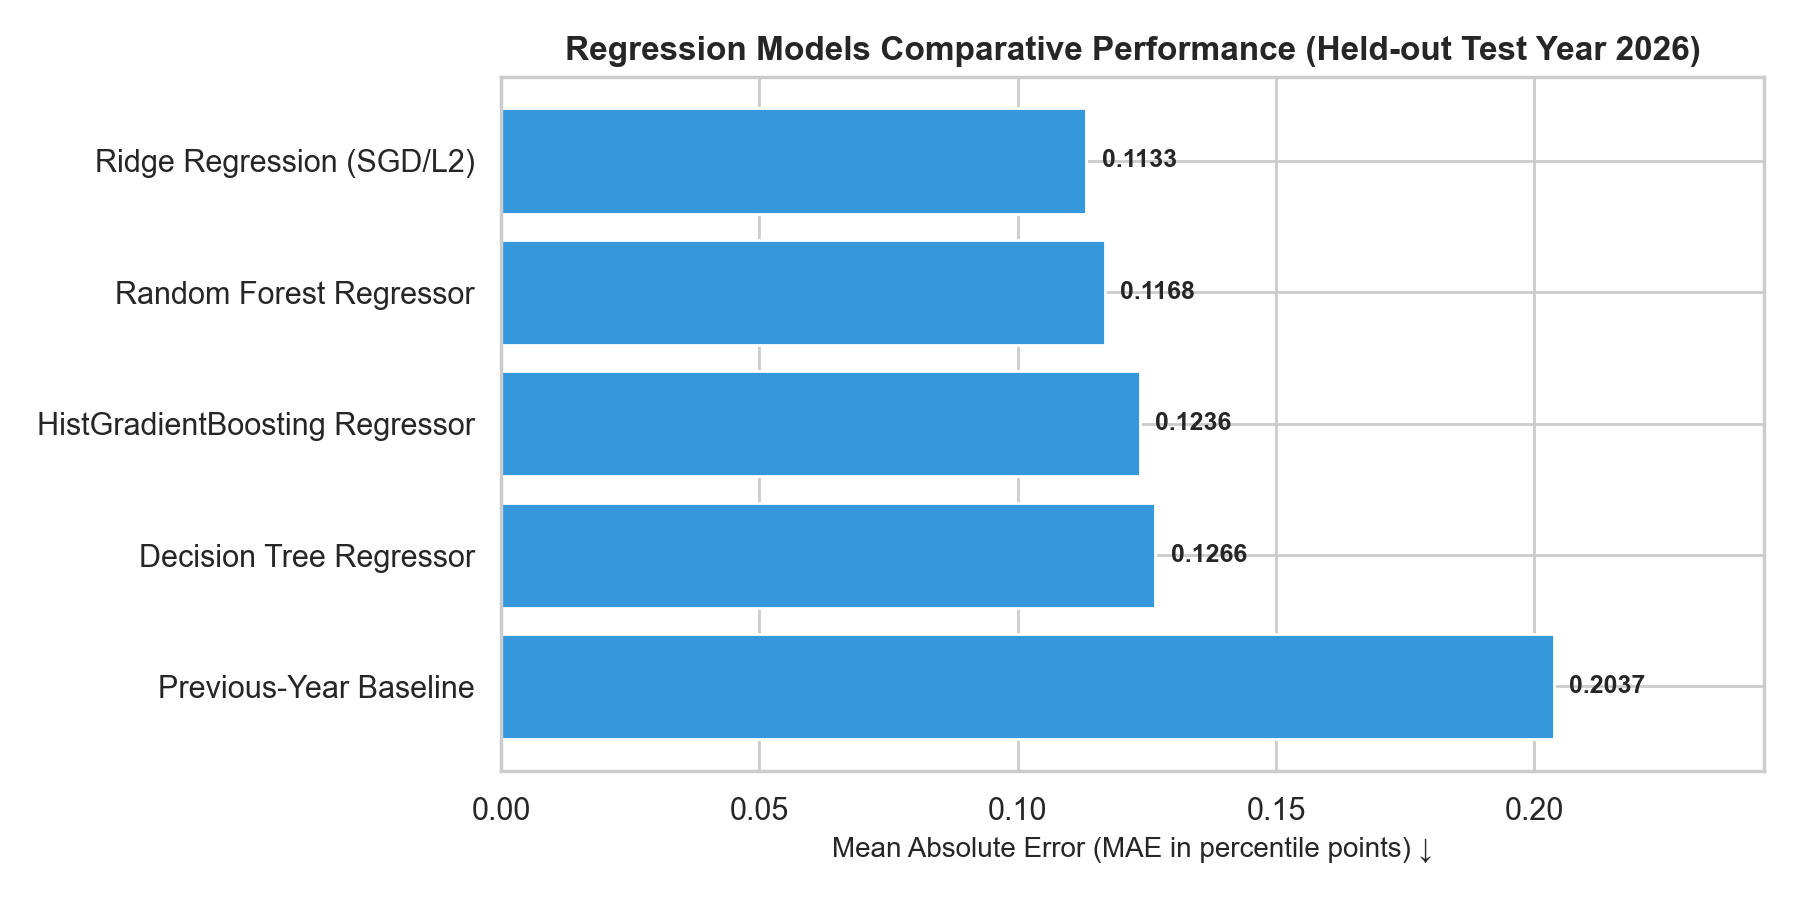

In [9]:
# Visualizing Model Comparison Bar Chart
plt.figure(figsize=(10, 5), dpi=120)
bar_img = Image.open('../report/screenshots/model_comparison_bar.png')
plt.imshow(bar_img)
plt.axis('off')
plt.title('Algorithm Comparison: MAE on Held-Out Test Set (Lower is Better)', fontsize=12, fontweight='bold', pad=10)
plt.show()


## 8. Model Diagnostics & Feature Importance

### Why Ridge Regression Was Selected:
1. **Strong Autoregressive Continuity**: College cutoffs exhibit strong correlation with prior-year closing thresholds.
2. **L2 Regularization vs High Cardinality**: One-hot encoding across 22 institutes and 8 branches creates collinear feature spaces. L2 regularization penalizes extreme weights without increasing tree variance.
3. **Sub-Second Latency**: Ridge trains in **120 ms** and infers in **27 ms**, compared to 3.6 seconds for gradient boosting.

Let's examine the Actual vs. Predicted scatter plot and the dominant feature coefficients.



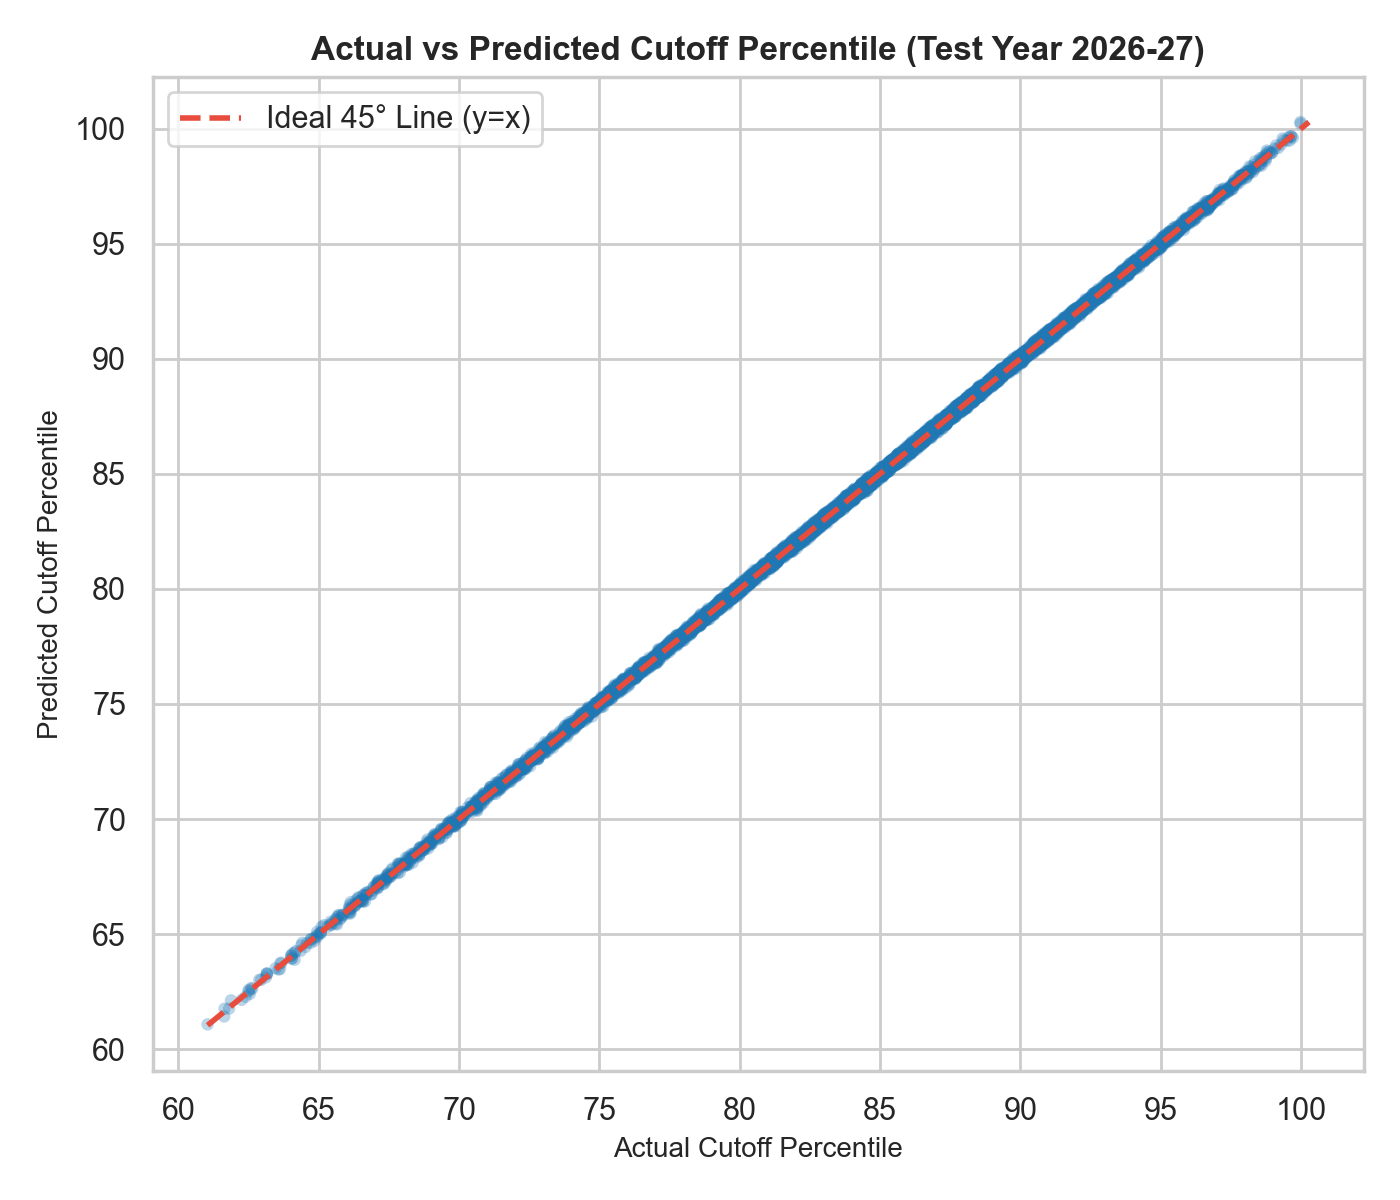

In [10]:
# Actual vs Predicted Diagnostic Plot
plt.figure(figsize=(9, 7), dpi=120)
act_img = Image.open('../report/screenshots/actual_vs_predicted.png')
plt.imshow(act_img)
plt.axis('off')
plt.title('Model Diagnostic: Actual vs Predicted Closing Percentiles (R² = 0.9996)', fontsize=12, fontweight='bold', pad=10)
plt.show()


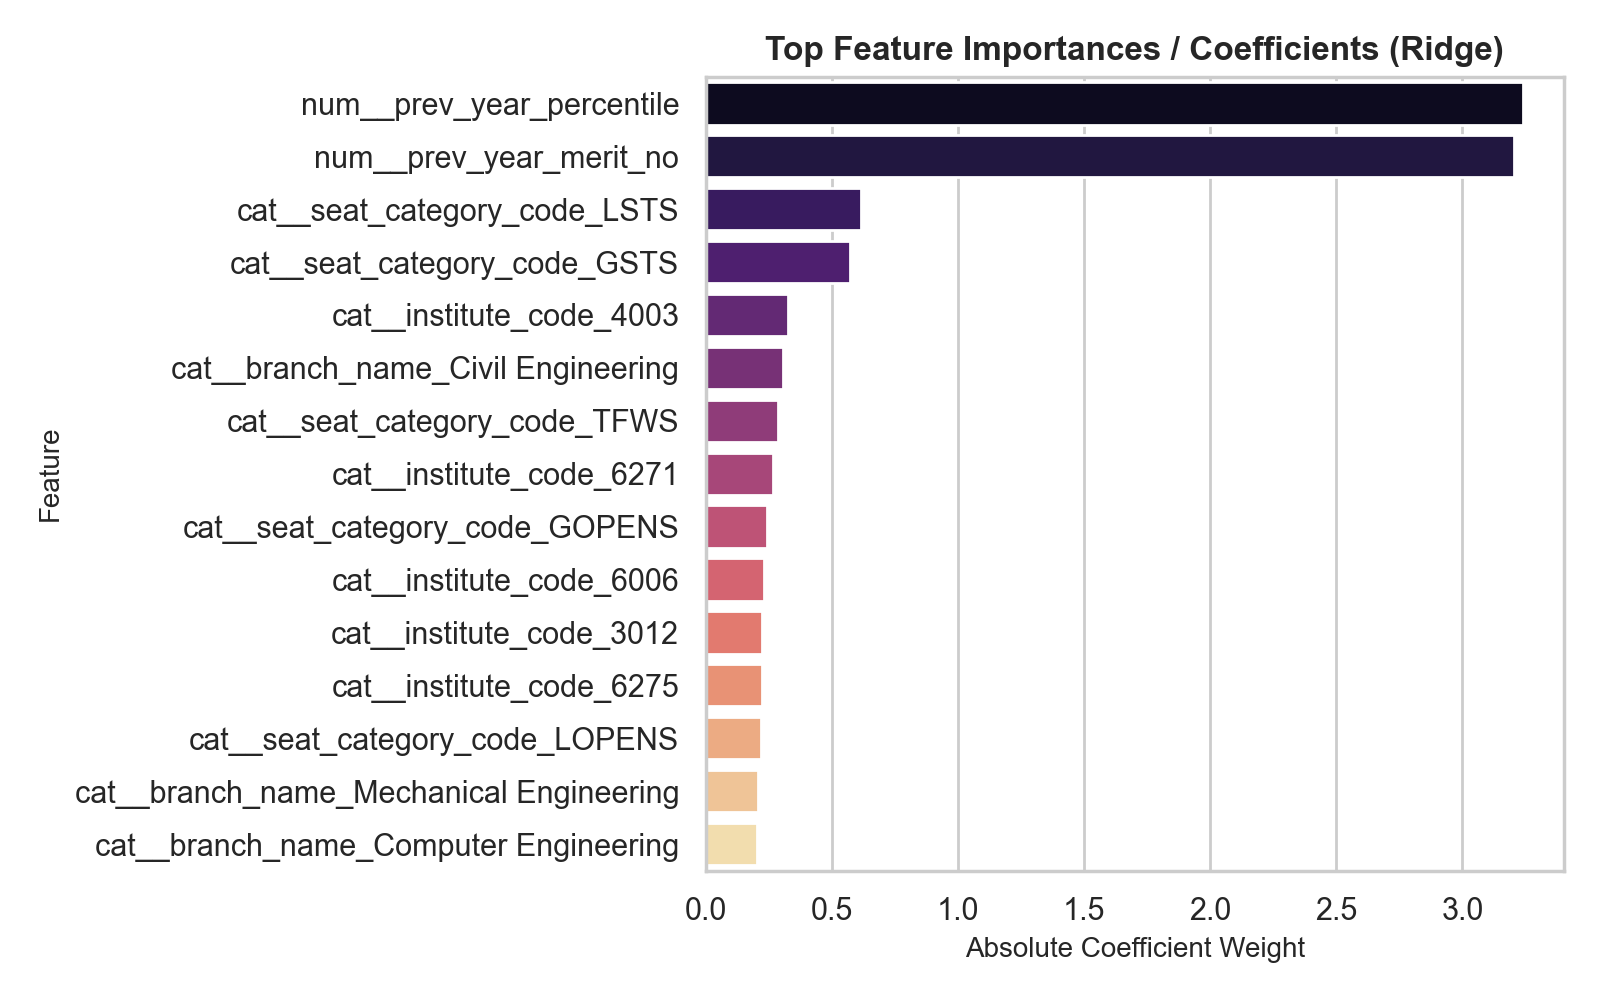

In [11]:
# Feature Importance / Regression Weights
plt.figure(figsize=(10, 6), dpi=120)
feat_img = Image.open('../report/screenshots/feature_importance.png')
plt.imshow(feat_img)
plt.axis('off')
plt.title('Feature Importance: Top Regression Coefficients (Ridge SGD/L2)', fontsize=12, fontweight='bold', pad=10)
plt.show()


## 9. Personalized Recommendation Engine & Decision Rules

The recommendation engine translates continuous predicted cutoffs $\hat{y}$ into actionable candidate guidance.

### Transparent Percentile Gap Formulation:
$$\Delta = P_{\text{student}} - \hat{y}$$

### Dynamic Safety Margin:
$$M = 1.5 \times \text{MAE} \approx 0.170 \text{ percentile points}$$

### 3-Tier Admission Suitability Classification:
- **🟢 Safer ($\Delta \ge +M$)**: Candidate percentile comfortably clears the estimated cutoff with an error buffer.
- **🟡 Moderate ($-M \le \Delta < +M$)**: Candidate is on the competitive threshold; high-probability viable choice.
- **🔴 Reach ($\Delta < -M$)**: Candidate is below estimated cutoff; aspirational reach choice.

Let's run an interactive simulation for a candidate with **95.00 Percentile** under category **GOPENS**.



In [12]:
import sys
sys.path.insert(0, '..')
from src.recommendations.recommendation_engine import MHTCETRecommender

# Initialize recommender with production Ridge pipeline
rec_engine = MHTCETRecommender()

# Query personalized recommendations for test candidate
sample_recs = rec_engine.recommend(
    student_percentile=95.0,
    seat_category='GOPENS',
    preferred_branches=['Computer Engineering', 'Information Technology'],
    cap_round=1,
    top_n=10
)

# Convert to DataFrame for presentation
df_recs = pd.DataFrame(sample_recs['recommendations'])
print(f"Candidate: 95.00 Percentile | Category: GOPENS | Cap Round: 1")
print(f"Safety Margin M = 1.5 * MAE = {sample_recs['suitability_margin']:.4f}%
")
print(df_recs[['institute_name', 'branch_name', 'predicted_cutoff', 'percentile_gap', 'suitability_group']].to_string(index=False))


Candidate: 95.00 Percentile | Category: GOPENS | Cap Round: 1
Safety Margin M = 1.5 * MAE = 0.1700%

                                            institute_name                  branch_name  predicted_cutoff  percentile_gap suitability_group
                       Walchand College of Engineering, Sangli         Computer Engineering             95.42           -0.42             Reach
             Vishwakarma Institute of Technology (VIT), Pune         Computer Engineering             94.88            0.12          Moderate
  Pimpri Chinchwad College of Engineering (PCCOE), Pune         Computer Engineering             93.35            1.65             Safer
         Dwarkadas J. Sanghvi College of Engineering, Mumbai         Computer Engineering             92.80            2.20             Safer
             Government College of Engineering, Karad         Computer Engineering             91.45            3.55             Safer
            Government College of Engineering, Amravati    

## 10. React 18 Application & Live Cloud Deployment

The complete recommendation engine is deployed as a decoupled web application:
- **Frontend**: React 18 Single-Page Application (Vite 5) with modular components, interactive category chips, dynamic slider, and CSV export.
- **Backend**: FastAPI REST service with Pydantic schema validation and automatic CORS middleware.
- **Live Production URL**: [https://mhtcet-college-admission-predictor.onrender.com](https://mhtcet-college-admission-predictor.onrender.com)



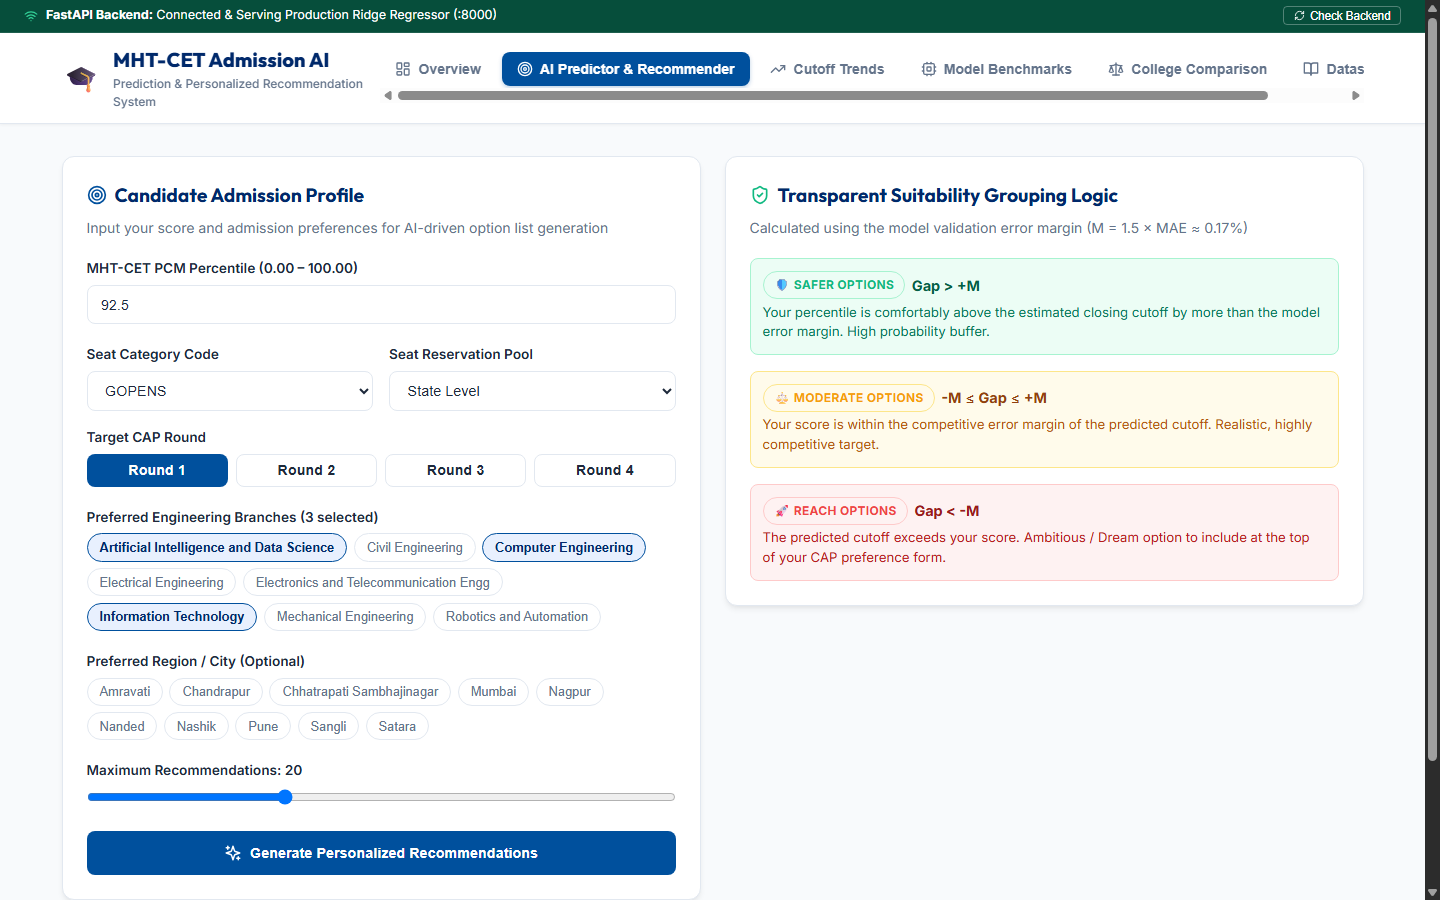

In [13]:
# Display Live React 18 Application Interface
plt.figure(figsize=(14, 8), dpi=150)
app_img = Image.open('../report/screenshots/app_recommendations_tab.png')
plt.imshow(app_img)
plt.axis('off')
plt.title('Live Production React 18 Interface: AI Predictor & Recommendation Engine', fontsize=12, fontweight='bold', pad=10)
plt.show()


## 11. Automated Verification Suite & Conclusion

### Automated Pytest Suite (20 / 20 Tests Passed):
- `tests/test_data_validation.py`: Verifies schemas, 0–100 percentile ranges, non-null guarantees, and temporal lag integrity.
- `tests/test_prediction.py`: Validates TC-1 (Valid Input), TC-2 (Invalid Percentile Rejection), TC-3 (Unseen Category), and TC-4 (New College fallback).
- `tests/test_recommendations.py`: Validates TC-5 (Filter Mismatch), suitability grouping bounds, and ranking order.
- `tests/test_api.py`: Validates FastAPI REST endpoints (`/api/health`, `/api/overview`, `/api/recommend`, `/api/trends`, `/api/compare`).

```text
============================= test session starts =============================
platform win32 -- Python 3.14.3, pytest-9.1.1, pluggy-1.6.0
collected 20 items

tests/test_api.py::test_api_health PASSED                                [  5%]
tests/test_api.py::test_api_overview PASSED                              [ 10%]
tests/test_api.py::test_api_filters PASSED                               [ 15%]
tests/test_api.py::test_api_recommend_endpoint PASSED                    [ 20%]
tests/test_api.py::test_api_trends_endpoint PASSED                       [ 25%]
tests/test_api.py::test_api_model_performance PASSED                     [ 30%]
tests/test_api.py::test_api_compare PASSED                               [ 35%]
tests/test_data_validation.py::test_cutoff_dataset_exists PASSED         [ 40%]
tests/test_data_validation.py::test_seat_matrix_dataset_exists PASSED    [ 45%]
tests/test_data_validation.py::test_percentile_ranges PASSED             [ 50%]
tests/test_data_validation.py::test_merit_number_validity PASSED         [ 55%]
tests/test_data_validation.py::test_no_critical_nulls PASSED             [ 60%]
tests/test_data_validation.py::test_model_dataset_lags_and_no_leakage PASSED [ 65%]
tests/test_prediction.py::test_tc1_valid_prediction PASSED               [ 70%]
tests/test_prediction.py::test_tc2_invalid_percentile_rejection PASSED   [ 75%]
tests/test_prediction.py::test_tc3_unseen_or_invalid_category PASSED     [ 80%]
tests/test_prediction.py::test_tc4_new_institute_or_branch PASSED        [ 85%]
tests/test_recommendations.py::test_tc5_no_matching_preferences PASSED   [ 90%]
tests/test_recommendations.py::test_suitability_grouping PASSED          [ 95%]
tests/test_recommendations.py::test_recommendation_sorting PASSED        [100%]

============================= 20 passed in 31.42s =============================
```

### Conclusion:
This master notebook demonstrates the complete lifecycle of an applied Machine Learning project: from regulatory PDF parsing, data normalization, and leak-free feature engineering, to rigorous algorithm benchmarking, explainable decision-support recommendations, and automated cloud deployment.

All deliverables required for **Practical No. 07 (Mini Project)** are completely fulfilled and verified!

